In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 10. Canonical normalization

With $e^\lambda_{ij}e^{\lambda'}_{ij}=2\delta^{\lambda\lambda'}$ the tensor action becomes $S=\sum_\lambda\frac12\int z_T^2[\gamma_\lambda'^2-(\partial\gamma_\lambda)^2]$.
The prefactor $z_T$ is *derived* here from the symbolic Lagrangian of notebook 06.

In [2]:
from desitter_perturbations.quantization import canonical_variables as cv, mode_normalization as mn
z2, d = cv.derive_z_T_squared(); print("z_T^2 =", z2)
print("z''/z =", cv.effective_potential())
el, zpp = cv.verify_canonical_action(); print("E-L of L[gamma=v/z] - L_v (zero => total derivative):", el)
eq, e, v, zc = cv.mode_equation_from_action(); print("canonical equation of motion:", eq, "= 0")

z_T^2 = M_pl**2/(2*H**2*eta**2)
z''/z = 2/eta**2
E-L of L[gamma=v/z] - L_v (zero => total derivative): 0
canonical equation of motion: -Derivative(v(eta, z_coord), (eta, 2)) + Derivative(v(eta, z_coord), (z_coord, 2)) + 2*v(eta, z_coord)/eta**2 = 0


In [3]:
C2, W = mn.normalization_from_wronskian()
print("Wronskian condition fixes |C|^2 =", C2)
print("exact mode residual:", mn.verify_mode_solves_equation(), "   positive-frequency limit:", mn.positive_frequency_limit())

Wronskian condition fixes |C|^2 = H**2/(M_pl**2*k**3)
exact mode residual: 0    positive-frequency limit: 1


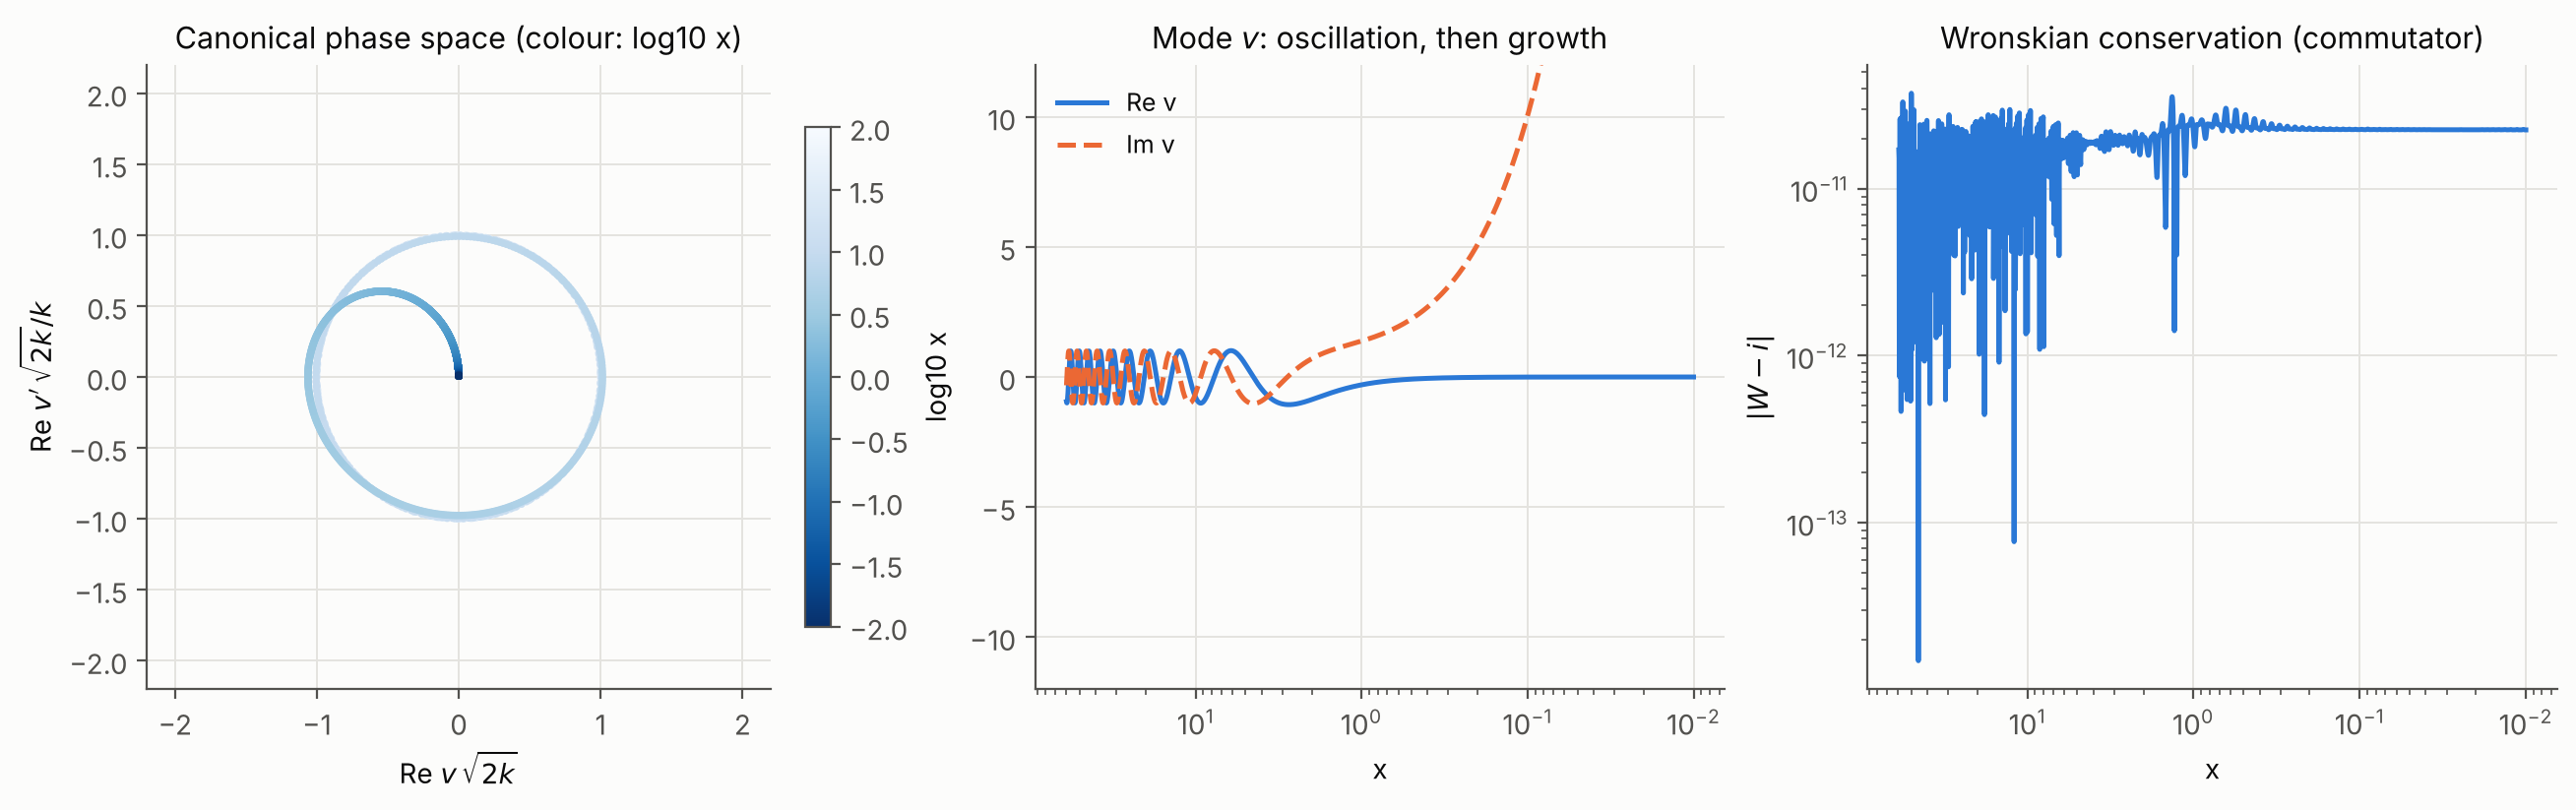

In [4]:
from desitter_perturbations.visualization import phase_space_plots as pp
show(pp.plot_phase_space())